#Machine Learning Model Comparison

#H3: Machine learning differ in their predictive performance and interpretability when predicting guest satisfaction



In [63]:
import pandas as pd
from pathlib import Path
import numpy as np
import re 
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
balanced_accuracy_score,
classification_report,
confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

datasets = [
    "gea_preprocessed",
    "pelagos_preprocessed",
    "gea_h2_drivers",
    "pelagos_h2_drivers"
]

for name in datasets:
    if name in globals():
        df = globals()[name]

        print(f"\nDataset: {name}")
        print("Shape:", df.shape)
        print("Columns:")
        print(df.columns.tolist())
        print("-" * 50)

In [2]:
print("Current folder:", Path.cwd())
print("\nAvailable datasets:")
for file in sorted(Path.cwd().iterdir()):
    if file.suffix.lower() in ["csv", ".xlsx", ".parquet", ".pkl"]:
        print(file.name)

Current folder: /home/8dff46cf-09d4-4d6f-9501-4575fba38b61/Business Analytics/Dissertation_METAS

Available datasets:
Gea_Feature_Engineering.xlsx
Gea_Preprocessed_All_Languages.xlsx
Gea_Preprocessed_English.xlsx
Gea_Reviews_2022_2026_Combined.xlsx
Pelagos_Feature_Engineering.xlsx
Pelagos_Preprocessed_All_Languages.xlsx
Pelagos_Preprocessed_English.xlsx
Pelagos_Reviews_2022_2026_Combined.xlsx


In [3]:
gea_ml = pd.read_excel("Gea_Feature_Engineering.xlsx")
pelagos_ml = pd.read_excel("Pelagos_Feature_Engineering.xlsx")
print("Gea Dataset")
print("Shape:", gea_ml.shape)
print("Columns:", gea_ml.columns.tolist())

print("\nPelagos Dataset")
print("Shape:", pelagos_ml.shape)
print("Columns:", pelagos_ml.columns.tolist())



Gea Dataset
Shape: (249, 35)
Columns: ['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'Response Submitted Date', 'Response Posted Date', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Review_Text', 'Review_Length', 'Short_Review', 'Satisfaction_Category', 'Review_Word_Count', 'Location_Clean', 'Guest_Country', 'Guest_Region']

Pelagos Dataset
Shape: (878, 34)
Columns: ['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Langu

In [4]:
for hotel_name, df in [
    ("Gea", gea_ml),
    ("Pelagos", pelagos_ml)
]:
    print(f"\n{'='*40}")
    print(f"{hotel_name.upper()} - TARGET VARIABLE")
    print(f"{'='*40}")

    print("\nRating distribution:")
    print(df["Rating"].value_counts(dropna=False).sort_index())

    print("\nSatisfaction categories:")
    print(df["Satisfaction_Category"].value_counts(dropna=False))

    print("\nMissing ratings:")
    print(df["Rating"].isna().sum())


GEA - TARGET VARIABLE

Rating distribution:
Rating
0.5      1
1.0      3
2.5      1
3.0      4
3.5      4
4.0     23
4.5      5
5.0    200
NaN      8
Name: count, dtype: int64

Satisfaction categories:
Satisfaction_Category
Satisfied        228
Neutral/Mixed      8
NaN                8
Dissatisfied       5
Name: count, dtype: int64

Missing ratings:
8

PELAGOS - TARGET VARIABLE

Rating distribution:
Rating
1.0     25
2.0     13
2.5      2
3.0     23
3.5      6
3.8      1
4.0     50
4.3      1
4.4      3
4.5     21
4.6      3
4.8      4
5.0    724
NaN      2
Name: count, dtype: int64

Satisfaction categories:
Satisfaction_Category
Satisfied        807
Dissatisfied      40
Neutral/Mixed     29
NaN                2
Name: count, dtype: int64

Missing ratings:
2


In [5]:
# Keeping reviews with valid ratings
gea_ml_clean = gea_ml.dropna(subset=["Rating"]).copy()
pelagos_ml_clean = pelagos_ml.dropna(subset=["Rating"]).copy()

# Binary classification target, 1 = Satisfied, 0 = Not satisfied

gea_ml_clean["Target"] = np.where(
    gea_ml_clean["Rating"] >= 4, 1, 0
)

pelagos_ml_clean["Target"] = np.where(
    pelagos_ml_clean["Rating"] >= 4, 1, 0
)

# Display class distributions
for name, df in [
    ("Gea", gea_ml_clean),
    ("Pelagos", pelagos_ml_clean)
]:
    print(f"\n{name.upper()}")

    print("Total reviews:", len(df))

    print("\nTarget distribution:")
    print(df["Target"].value_counts().sort_index())

    print("\nTarget percentages:")
    print(
        (df["Target"].value_counts(normalize=True)
         .sort_index() * 100).round(2)
    )


GEA
Total reviews: 241

Target distribution:
Target
0     13
1    228
Name: count, dtype: int64

Target percentages:
Target
0     5.39
1    94.61
Name: proportion, dtype: float64

PELAGOS
Total reviews: 876

Target distribution:
Target
0     70
1    806
Name: count, dtype: int64

Target percentages:
Target
0     7.99
1    92.01
Name: proportion, dtype: float64


In [6]:
for hotel, df in [
    ("Gea", gea_ml_clean),
    ("Pelagos", pelagos_ml_clean)
]:
    
    print("\n--------------------------------------")
    print(hotel, "-Text Availability")
    print("------------------------------------")
    
    print("Total Reviews:", len(df))
    
    if "Clean_Text" in df.columns:
        text_column = "Clean_Text"
    else:
        text_column = "Review_Text"
    print("Text column used:", text_column)
    
    usable = (
       df[text_column]
       .fillna("")
       .astype(str)
       .str.strip()
       .ne("")

    )
    print("Reviews with usable text:", usable.sum())
    print("Reviews without usable text:", (usable).sum())


--------------------------------------
Gea -Text Availability
------------------------------------
Total Reviews: 241
Text column used: Review_Text
Reviews with usable text: 241
Reviews without usable text: 241

--------------------------------------
Pelagos -Text Availability
------------------------------------
Total Reviews: 876
Text column used: Clean_Text
Reviews with usable text: 876
Reviews without usable text: 876


In [7]:
print("Gea Text Columns:")
print([col for col in gea_ml_clean.columns
       if "text" in col.lower() or "review" in col.lower()])
print("\nPelagos Text Columns:")
print([col for col in pelagos_ml_clean.columns
       if "text" in col.lower() or "review" in col.lower()])

Gea Text Columns:
['Review Site', 'Review Date', 'Review Title', 'Review', 'Review Link', 'Review ID', 'Review_Text', 'Review_Length', 'Short_Review', 'Review_Word_Count']

Pelagos Text Columns:
['Review Site', 'Review Date', 'Review Title', 'Review', 'Review Link', 'Review ID', 'Review_Text', 'Review_Length', 'Clean_Text', 'Short_Review', 'Review_Word_Count']


In [8]:
for hotel, df in [
    ("Gea", gea_ml_clean),
    ("Pelagos", pelagos_ml_clean)
]:
    text_col = (
        "Clean_Text"
        if "Clean_Text" in df.columns
        else "Review_Text"
    )

    text = df[text_col].fillna("").astype(str).str.strip()
    usable = text.ne("")

    print("\n", hotel)
    print("Text column:", text_col)
    print("Total reviews:", len(df))
    print("Usable text:", usable.sum())
    print("Unusable text:", (~usable).sum())
 


 Gea
Text column: Review_Text
Total reviews: 241
Usable text: 241
Unusable text: 0

 Pelagos
Text column: Clean_Text
Total reviews: 876
Usable text: 876
Unusable text: 0


In [9]:
print("Gea_Text_sample")
print(gea_ml_clean["Review_Text"].iloc[0])

print("\nPelagos_Text_sample")
print(pelagos_ml_clean["Clean_Text"].iloc[0])

Gea_Text_sample
Excellent. Good: staff  location    Bad: we didn’t receive the honeymoon suite as promised.

Pelagos_Text_sample
the best way to experience santorini… this hotel is absolutely amazing. the suites and the views are incredible. i just want to thank everyone at the hotel that helped to make our stay at the katikies santorini such a memorable one. from the moment we arrived, we were treated with such great customer service. yvonne, who was working the registration desk, had informed us that we were being upgraded to the honeymoon suite free of charge because we were celebrating our first wedding anniversary. we were ecstatic. but we had no idea what was in store for us once we finally reached the suite. the suite was amazing and the view from it was unbelievable. watching the sunset from our terrace that first evening was unreal. every morning we woke up was like a dream come true for us. my husband especially loved the orange juice that was served with our complimentary br

In [10]:
gea_ml_ready = gea_ml_clean.copy()
pelagos_ml_ready = pelagos_ml_clean.copy()


def prepare_ml_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


gea_ml_ready["ML_Text"] = (
    gea_ml_ready["Review_Text"]
    .apply(prepare_ml_text)
)

pelagos_ml_ready["ML_Text"] = (
    pelagos_ml_ready["Clean_Text"]
    .apply(prepare_ml_text)
)


for hotel, df in [
    ("Gea", gea_ml_ready),
    ("Pelagos", pelagos_ml_ready)
]:
    print(f"\n{hotel}")
    print("Total reviews:", len(df))
    print("Usable ML text:",
          df["ML_Text"].ne("").sum())
    print("Sample:", df["ML_Text"].iloc[0][:250])


Gea
Total reviews: 241
Usable ML text: 236
Sample: excellent good staff location bad we didn t receive the honeymoon suite as promised

Pelagos
Total reviews: 876
Usable ML text: 813
Sample: the best way to experience santorini this hotel is absolutely amazing the suites and the views are incredible i just want to thank everyone at the hotel that helped to make our stay at the katikies santorini such a memorable one from the moment we ar


In [11]:
gea_ml_final = gea_ml_ready[
    (gea_ml_ready["ML_Text"].str.strip() != "") &
    (gea_ml_ready["Satisfaction_Category"].notna())
].copy()

pelagos_ml_final = pelagos_ml_ready[
    (pelagos_ml_ready["ML_Text"].str.strip() != "") &
    (pelagos_ml_ready["Satisfaction_Category"].notna())
].copy()

# Binary target: 1 = Satisfied, 0 = Other
for df in [gea_ml_final, pelagos_ml_final]:
    df["Target"] = (
        df["Satisfaction_Category"] == "Satisfied"
    ).astype(int)

# Final sample sizes and class distributions
for hotel, df in [
    ("Gea", gea_ml_final),
    ("Pelagos", pelagos_ml_final)
]:
    print(f"\n{'='*40}")
    print(hotel.upper())
    print("Final reviews:", len(df))
    print("\nTarget distribution:")
    print(df["Target"].value_counts())
    print("\nTarget percentages:")
    print(
        (df["Target"].value_counts(normalize=True) * 100)
        .round(2)
    )



GEA
Final reviews: 236

Target distribution:
Target
1    223
0     13
Name: count, dtype: int64

Target percentages:
Target
1    94.49
0     5.51
Name: proportion, dtype: float64

PELAGOS
Final reviews: 813

Target distribution:
Target
1    744
0     69
Name: count, dtype: int64

Target percentages:
Target
1    91.51
0     8.49
Name: proportion, dtype: float64


In [12]:
# GEA
X_gea = gea_ml_final["ML_Text"]
y_gea = gea_ml_final["Target"]

X_gea_train, X_gea_test, y_gea_train, y_gea_test = train_test_split(
    X_gea,
    y_gea,
    test_size=0.20,
    random_state=42,
    stratify=y_gea
)

# PELAGOS
X_pelagos = pelagos_ml_final["ML_Text"]
y_pelagos = pelagos_ml_final["Target"]

X_pelagos_train, X_pelagos_test, y_pelagos_train, y_pelagos_test = train_test_split(
    X_pelagos,
    y_pelagos,
    test_size=0.20,
    random_state=42,
    stratify=y_pelagos
)

# Checking the splits
for hotel, y_train, y_test in [
    ("GEA", y_gea_train, y_gea_test),
    ("PELAGOS", y_pelagos_train, y_pelagos_test)
]:
    print(f"\n{'=' * 40}")
    print(hotel)
    print("Training reviews:", len(y_train))
    print("Testing reviews:", len(y_test))

    print("\nTraining target distribution:")
    print(y_train.value_counts().sort_index())

    print("\nTesting target distribution:")
    print(y_test.value_counts().sort_index())


GEA
Training reviews: 188
Testing reviews: 48

Training target distribution:
Target
0     10
1    178
Name: count, dtype: int64

Testing target distribution:
Target
0     3
1    45
Name: count, dtype: int64

PELAGOS
Training reviews: 650
Testing reviews: 163

Training target distribution:
Target
0     55
1    595
Name: count, dtype: int64

Testing target distribution:
Target
0     14
1    149
Name: count, dtype: int64


In [13]:
# First model
def create_logistic_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=3000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
     ])

# Train Gea model
gea_lr = create_logistic_model()
gea_lr.fit(X_gea_train, y_gea_train)

# Train Pelagos model
pelagos_lr = create_logistic_model()
pelagos_lr.fit(X_pelagos_train, y_pelagos_train)

print("Gea: Logistic Regression trained successfully!")
print("Pelagos: Logistic Regression trained successfully!")

Gea: Logistic Regression trained successfully!
Pelagos: Logistic Regression trained successfully!


In [14]:
def evaluate_model(model, X_test, y_test, hotel):
   y_pred = model.predict(X_test)

   print(f"\n{'='*45}")
   print(f"{hotel.upper()} - LOGISTIC REGRESSION")
   print(f"{'='*45}")

   print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
   print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
   print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
   print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
   print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))

   print("\nClassification Report:")
   print(classification_report(y_test, y_pred, zero_division=0))

   print("\nConfusion Matrix:")
   print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

# Evaluate Gea
evaluate_model(
    gea_lr,
    X_gea_test,
    y_gea_test,
    "Gea"
)

# Evaluate Pelagos
evaluate_model(
    pelagos_lr,
    X_pelagos_test,
    y_pelagos_test,
    "Pelagos"
)


GEA - LOGISTIC REGRESSION
Accuracy: 0.9583
Precision: 0.9778
Recall: 0.9778
F1-score: 0.9778
Balanced Accuracy: 0.8222

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.67      0.67         3
           1       0.98      0.98      0.98        45

    accuracy                           0.96        48
   macro avg       0.82      0.82      0.82        48
weighted avg       0.96      0.96      0.96        48


Confusion Matrix:
[[ 2  1]
 [ 1 44]]

PELAGOS - LOGISTIC REGRESSION
Accuracy: 0.9509
Precision: 0.9669
Recall: 0.9799
F1-score: 0.9733
Balanced Accuracy: 0.8114

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.64      0.69        14
           1       0.97      0.98      0.97       149

    accuracy                           0.95       163
   macro avg       0.86      0.81      0.83       163
weighted avg       0.95      0.95      0.95       163


Confusion Matri

In [19]:
def create_random_forest_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True
         )),
         ("classifier", RandomForestClassifier(
             n_estimators=200,
             class_weight="balanced",
             random_state=42,
             n_jobs=-1
          ))
     ])

# Train Gea Random Forest
gea_rf = create_random_forest_model()
gea_rf.fit(X_gea_train, y_gea_train)

# Train Pelagos Random Forest
pelagos_rf = create_random_forest_model()
pelagos_rf.fit(X_pelagos_train, y_pelagos_train)

print("Gea: Random Forest trained successfully!")
print("Pelagos: Random Forest trained successfully!")


Gea: Random Forest trained successfully!
Pelagos: Random Forest trained successfully!


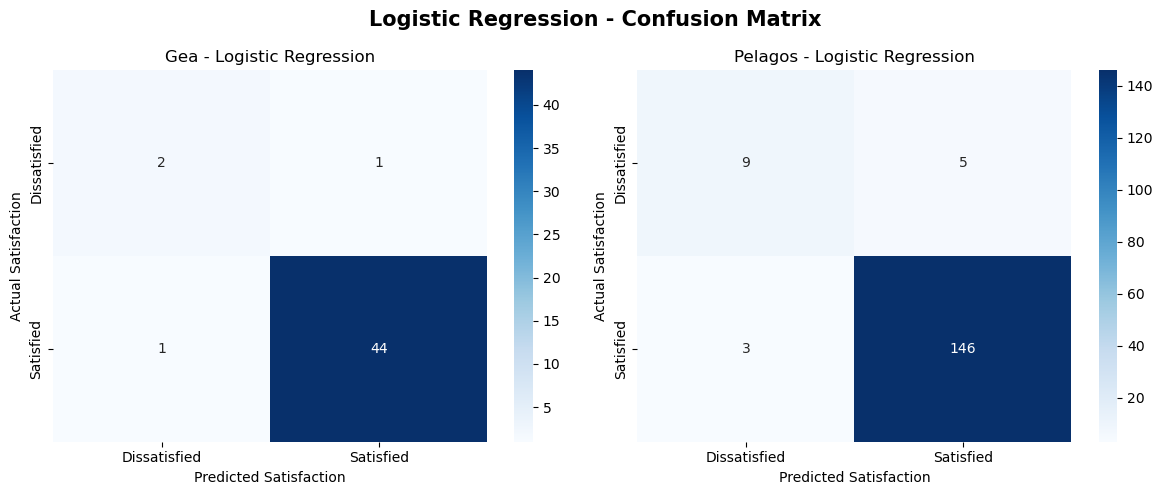

In [50]:
# Predictions
gea_pred = gea_lr.predict(X_gea_test)
pelagos_pred = pelagos_lr.predict(X_pelagos_test)

# Confusion matrices
gea_cm = confusion_matrix(y_gea_test, gea_pred, labels=[0, 1])
pelagos_cm = confusion_matrix(y_pelagos_test, pelagos_pred, labels=[0, 1])

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    gea_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Dissatisfied", "Satisfied"],
    yticklabels=["Dissatisfied", "Satisfied"],
    ax=axes[0]
)

sns.heatmap(
    pelagos_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Dissatisfied", "Satisfied"],
    yticklabels=["Dissatisfied", "Satisfied"],
    ax=axes[1]
)

axes[0].set_title("Gea - Logistic Regression")
axes[1].set_title("Pelagos - Logistic Regression")

for ax in axes:
    ax.set_xlabel("Predicted Satisfaction")
    ax.set_ylabel("Actual Satisfaction")

plt.suptitle(
    "Logistic Regression - Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "Logistic_Regression_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

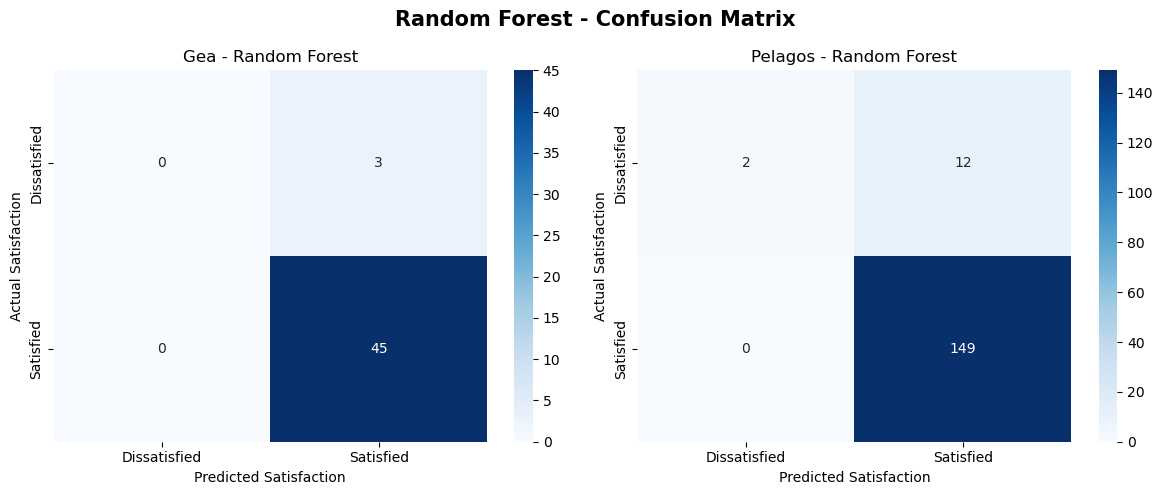

In [49]:
# Random Forest predictions
gea_rf_pred = gea_rf.predict(X_gea_test)
pelagos_rf_pred = pelagos_rf.predict(X_pelagos_test)

# Confusion matrics
gea_rf_cm = confusion_matrix(
    y_gea_test, gea_rf_pred, labels=[0, 1]
)

pelagos_rf_cm = confusion_matrix(
    y_pelagos_test, pelagos_rf_pred, labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    gea_rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dissatisfied", "Satisfied"],
    yticklabels=["Dissatisfied", "Satisfied"],
    ax=axes[0]
)

sns.heatmap(
    pelagos_rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dissatisfied", "Satisfied"],
    yticklabels=["Dissatisfied", "Satisfied"],
    ax=axes[1]
)

axes[0].set_title("Gea - Random Forest")
axes[1].set_title("Pelagos - Random Forest")

for ax in axes:
    ax.set_xlabel("Predicted Satisfaction")
    ax.set_ylabel("Actual Satisfaction")

plt.suptitle(
    "Random Forest - Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Random_Forest_Confusion_Matrix.png",
     dpi=300,
     bbox_inches="tight"
)
plt.show()

In [29]:
all_models = [
    ("Gea", "Logistic Regression", gea_lr,
     X_gea_test, y_gea_test),

    ("Gea", "Random Forest", gea_rf,
     X_gea_test, y_gea_test),

    ("Pelagos", "Logistic Regression", pelagos_lr,
     X_pelagos_test, y_pelagos_test),

    ("Pelagos", "Random Forest", pelagos_rf,
     X_pelagos_test, y_pelagos_test)
]

comparison_results = []

for hotel, model_name, model, X_test, y_test in all_models:
    predictions = model.predict(X_test)

    comparison_results.append({
       "Hotel": hotel,
       "Model": model_name,
       "Accuracy": accuracy_score(y_test, predictions),
       "Precision": precision_score(
           y_test, predictions, zero_division=0),
       "Recall": recall_score(
           y_test, predictions, zero_division=0),
       "F1-score": f1_score(
           y_test, predictions, zero_division=0),
       "Balanced Accuracy": balanced_accuracy_score(
           y_test, predictions),
       "Dissatisfied Recall": recall_score(
           y_test, predictions,
           pos_label=0, zero_division=0)
   })

comparison_df = pd.DataFrame(comparison_results)

print("Number of models evaluated:", len(comparison_df))
display(comparison_df.round(3))

comparison_df.to_csv("ML_Model_Comparison.csv", index=False)

Number of models evaluated: 4


,Hotel,Model,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Dissatisfied Recall
0,Gea,Logistic Regression,0.958,0.978,0.978,0.978,0.822,0.667
1,Gea,Random Forest,0.938,0.938,1.000,0.968,0.500,0.000
2,Pelagos,Logistic Regression,0.951,0.967,0.980,0.973,0.811,0.643
3,Pelagos,Random Forest,0.926,0.925,1.000,0.961,0.571,0.143


In [32]:
# Create SVM model
def create_svm_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True
         )),
         ("classifier", LinearSVC(
             class_weight="balanced",
             random_state=42,
             max_iter=5000
         ))
      ])

# Train SVM for Gea
gea_svm = create_svm_model()
gea_svm.fit(X_gea_train, y_gea_train)

# Train SVM for Pelagos
pelagos_svm = create_svm_model()
pelagos_svm.fit(X_pelagos_train, y_pelagos_train)

print("Gea: SVM trained successfully!")
print("Pelagos: SVM trained successfully!")

Gea: SVM trained successfully!
Pelagos: SVM trained successfully!


In [33]:
svm_models = [
    ("Gea", gea_svm, X_gea_test, y_gea_test),
    ("Pelagos", pelagos_svm, X_pelagos_test, y_pelagos_test)
]

for hotel, model, X_test, y_test in svm_models:

    y_pred = model.predict(X_test)

    print("\n" + "=" * 45)
    print(f"{hotel.upper()} - SUPPORT VECTOR MACHINE")
    print("=" * 45)

    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(
        y_test, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(
        y_test, y_pred, zero_division=0), 4))
    print("F1-score:", round(f1_score(
        y_test, y_pred, zero_division=0), 4))
    print("Balanced Accuracy:", round(
        balanced_accuracy_score(y_test, y_pred), 4))
    print("Dissatisfied Recall:", round(
        recall_score(y_test, y_pred,
                     pos_label=0, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Dissatisfied", "Satisfied"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))


GEA - SUPPORT VECTOR MACHINE
Accuracy: 0.9167
Precision: 0.9362
Recall: 0.9778
F1-score: 0.9565
Balanced Accuracy: 0.4889
Dissatisfied Recall: 0.0

PELAGOS - SUPPORT VECTOR MACHINE
Accuracy: 0.9325
Precision: 0.9367
Recall: 0.9933
F1-score: 0.9642
Balanced Accuracy: 0.6395
Dissatisfied Recall: 0.2857

Classification Report:
              precision    recall  f1-score   support

Dissatisfied       0.80      0.29      0.42        14
   Satisfied       0.94      0.99      0.96       149

    accuracy                           0.93       163
   macro avg       0.87      0.64      0.69       163
weighted avg       0.92      0.93      0.92       163

Confusion Matrix:
[[  4  10]
 [  1 148]]


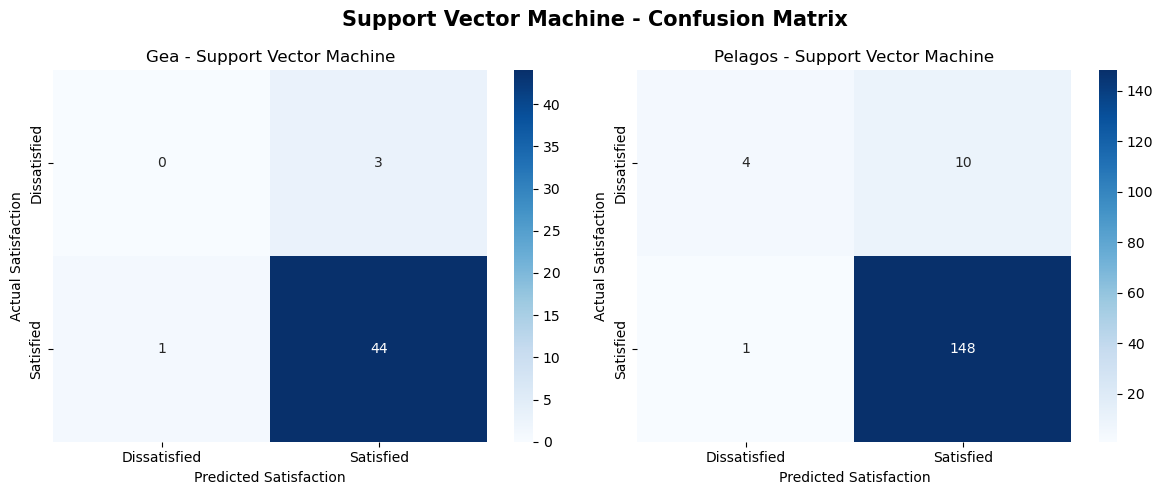

In [48]:
# SVM predictions
gea_svm_pred = gea_svm.predict(X_gea_test)
pelagos_svm_pred = pelagos_svm.predict(X_pelagos_test)

# Confusion matrices
gea_svm_cm = confusion_matrix(
    y_gea_test, gea_svm_pred, labels=[0, 1]
)

pelagos_svm_cm = confusion_matrix(
    y_pelagos_test, pelagos_svm_pred, labels=[0, 1]
)

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, hotel in zip(
    axes,
    [gea_svm_cm, pelagos_svm_cm],
    ["Gea", "Pelagos"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Dissatisfied", "Satisfied"],
        yticklabels=["Dissatisfied", "Satisfied"],
        ax=ax
    )

    ax.set_title(f"{hotel} - Support Vector Machine")
    ax.set_xlabel("Predicted Satisfaction")
    ax.set_ylabel("Actual Satisfaction")

plt.suptitle(
    "Support Vector Machine - Confusion Matrix",
     fontsize=15,
     fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "SVM_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# Create Naive Bayes model
def create_nb_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True
    )),
    ("classifier", MultinomialNB(alpha=1.0))
])

# Train Naive Bayes for Gea
gea_nb = create_nb_model()
gea_nb.fit(X_gea_train, y_gea_train)

# Train Naive Bayes for Pelagos
pelagos_nb = create_nb_model()
pelagos_nb.fit(X_pelagos_train, y_pelagos_train)

print("Gea: Naive Bayes trained successfully!")
print("Pelagos: Naive Bayes trained successfully!")

Gea: Naive Bayes trained successfully!
Pelagos: Naive Bayes trained successfully!


In [37]:
# Evaluate Naive Bayes for both hotels
for hotel, model, X_test, y_test in [
    ("Gea", gea_nb, X_gea_test, y_gea_test),
    ("Pelagos", pelagos_nb, X_pelagos_test, y_pelagos_test)
]:
    predictions = model.predict(X_test)

    print("=" * 50)
    print(f"{hotel.upper()} - NAIVE BAYES")
    print("=" * 50)

    print("Accuracy:",
          round(accuracy_score(y_test, predictions), 4))
    print("Precision:",
          round(precision_score(y_test, predictions, zero_division=0), 4))
    print("Recall:",
          round(recall_score(y_test, predictions, zero_division=0), 4))
    print("F1-score:",
          round(f1_score(y_test, predictions, zero_division=0), 4))
    print("Balanced Accuracy:",
          round(balanced_accuracy_score(y_test, predictions), 4))
    print("Dissatisfied Recall:",
          round(recall_score(
               y_test, predictions,
               pos_label=0, zero_division=0
          ), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["Dissatisfied", "Satisfied"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test, predictions, labels=[0, 1]
     ))

GEA - NAIVE BAYES
Accuracy: 0.9375
Precision: 0.9375
Recall: 1.0
F1-score: 0.9677
Balanced Accuracy: 0.5
Dissatisfied Recall: 0.0

Classification Report:
              precision    recall  f1-score   support

Dissatisfied       0.00      0.00      0.00         3
   Satisfied       0.94      1.00      0.97        45

    accuracy                           0.94        48
   macro avg       0.47      0.50      0.48        48
weighted avg       0.88      0.94      0.91        48

Confusion Matrix:
[[ 0  3]
 [ 0 45]]
PELAGOS - NAIVE BAYES
Accuracy: 0.9141
Precision: 0.9141
Recall: 1.0
F1-score: 0.9551
Balanced Accuracy: 0.5
Dissatisfied Recall: 0.0

Classification Report:
              precision    recall  f1-score   support

Dissatisfied       0.00      0.00      0.00        14
   Satisfied       0.91      1.00      0.96       149

    accuracy                           0.91       163
   macro avg       0.46      0.50      0.48       163
weighted avg       0.84      0.91      0.87       16

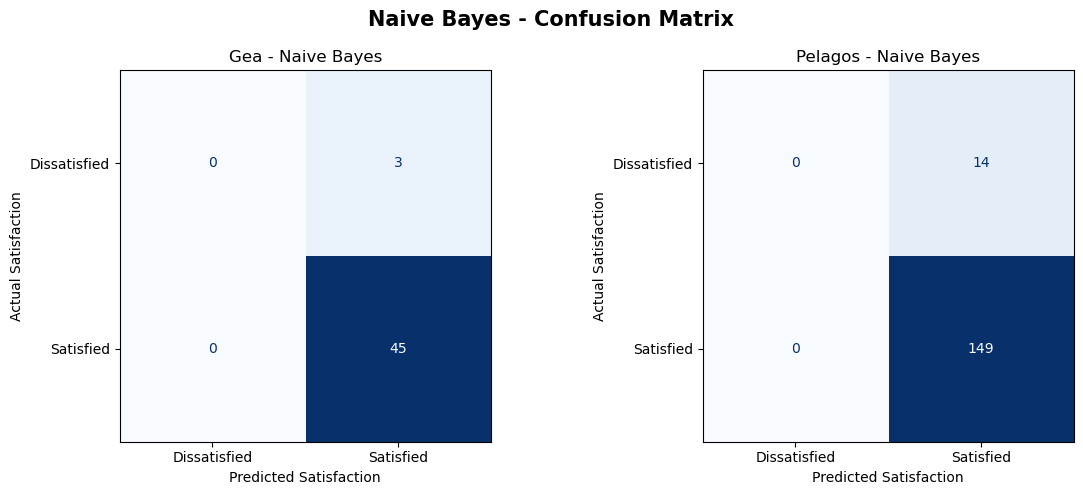

In [47]:
# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gea
ConfusionMatrixDisplay.from_predictions(
    y_gea_test,
    gea_nb.predict(X_gea_test),
    labels=[0, 1],
    display_labels=["Dissatisfied", "Satisfied"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title("Gea - Naive Bayes")
axes[0].set_xlabel("Predicted Satisfaction")
axes[0].set_ylabel("Actual Satisfaction")

# Pelagos
ConfusionMatrixDisplay.from_predictions(
    y_pelagos_test,
    pelagos_nb.predict(X_pelagos_test),
    labels=[0, 1],
   display_labels=["Dissatisfied", "Satisfied"],
   cmap="Blues",
   colorbar=False,
   ax=axes[1]
)

axes[1].set_title("Pelagos - Naive Bayes")
axes[1].set_xlabel("Predicted Satisfaction")
axes[1].set_ylabel("Actual Satisfaction")

# Final formatting
plt.suptitle(
    "Naive Bayes - Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "Naive_Bayes_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [51]:
# All eight trained models
models = [
    ("Gea", "Logistic Regression", gea_lr,
     X_gea_test, y_gea_test),
    ("Gea", "Random Forest", gea_rf,
     X_gea_test, y_gea_test),
    ("Gea", "SVM", gea_svm,
     X_gea_test, y_gea_test),
    ("Gea", "Naive Bayes", gea_nb,
     X_gea_test, y_gea_test),
    ("Pelagos", "Logistic Regression", pelagos_lr,
     X_pelagos_test, y_pelagos_test),
    ("Pelagos", "Random Forest", pelagos_rf,
     X_pelagos_test, y_pelagos_test),
    ("Pelagos", "SVM", pelagos_svm,
     X_pelagos_test, y_pelagos_test),
    ("Pelagos", "Naive Bayes", pelagos_nb,
     X_pelagos_test, y_pelagos_test)
]

# Calculate performance metrics
results = []

for hotel, name, model, X_test, y_test in models:
    predictions = model.predict(X_test)

    results.append({
        "Hotel": hotel,
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0),
        "Recall": recall_score(
            y_test, predictions, zero_division=0),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions),
        "Dissatisfied Recall": recall_score(
            y_test, predictions,
           pos_label=0, zero_division=0)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(3))

# Save for dissertation
comparison_df.to_csv(
    "Final_ML_Model_Comparison.csv",
    index=False
)

,Hotel,Model,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Dissatisfied Recall
0,Gea,Logistic Regression,0.958,0.978,0.978,0.978,0.822,0.667
1,Gea,Random Forest,0.938,0.938,1.000,0.968,0.500,0.000
2,Gea,SVM,0.917,0.936,0.978,0.957,0.489,0.000
3,Gea,Naive Bayes,0.938,0.938,1.000,0.968,0.500,0.000
4,Pelagos,Logistic Regression,0.951,0.967,0.980,0.973,0.811,0.643
5,Pelagos,Random Forest,0.926,0.925,1.000,0.961,0.571,0.143
6,Pelagos,SVM,0.933,0.937,0.993,0.964,0.640,0.286
7,Pelagos,Naive Bayes,0.914,0.914,1.000,0.955,0.500,0.000


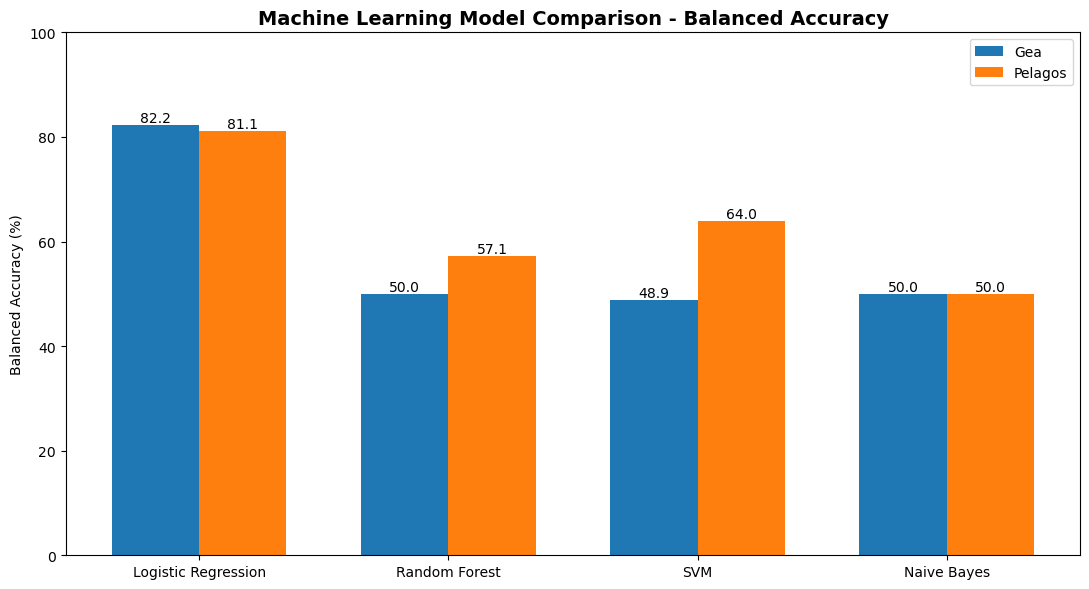

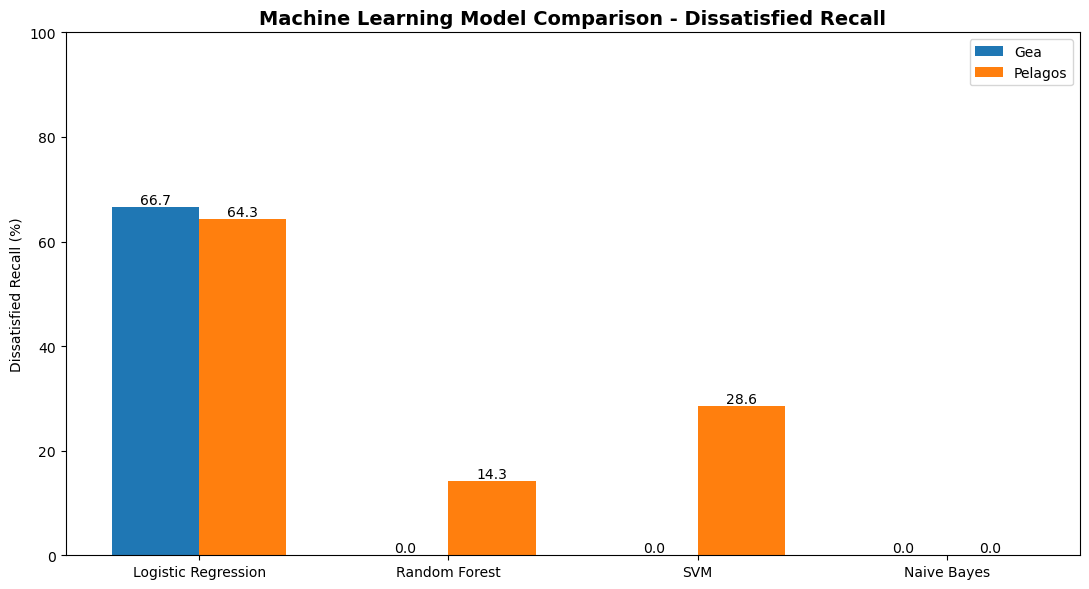

In [52]:
# Set model order
model_order = [
    "Logistic Regression",
    "Random Forest",
    "SVM",
    "Naive Bayes"
]

gea = comparison_df[
    comparison_df["Hotel"] == "Gea"
].set_index("Model").loc[model_order]

pelagos = comparison_df[
    comparison_df["Hotel"] == "Pelagos"
].set_index("Model").loc[model_order]

x = np.arange(len(model_order))
width = 0.35

# Figure 1: Balanced Accuracy
fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width/2,
    gea["Balanced Accuracy"] * 100,
    width,
    label="Gea"
)

bars2 = ax.bar(
    x + width/2,
    pelagos["Balanced Accuracy"] * 100,
    width,
    label="Pelagos"
)

ax.set_title(
    "Machine Learning Model Comparison - Balanced Accuracy",
    fontsize=14,
    fontweight="bold"
)
ax.set_ylabel("Balanced Accuracy (%)")
ax.set_xticks(x)
ax.set_xticklabels(model_order)
ax.set_ylim(0, 100)
ax.legend()
ax.bar_label(bars1, fmt="%.1f")
ax.bar_label(bars2, fmt="%.1f")

plt.tight_layout()
plt.savefig(
    "ML_Balanced_Accuracy_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 2: Dissatisfied Recall
fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width/2,
    gea["Dissatisfied Recall"] * 100,
    width,
    label="Gea"
)

bars2 = ax.bar(
    x + width/2,
    pelagos["Dissatisfied Recall"] * 100,
    width,
    label="Pelagos"
)

ax.set_title(
    "Machine Learning Model Comparison - Dissatisfied Recall",
    fontsize=14,
    fontweight="bold"
)
ax.set_ylabel("Dissatisfied Recall (%)")
ax.set_xticks(x)
ax.set_xticklabels(model_order)
ax.set_ylim(0, 100)
ax.legend()
ax.bar_label(bars1, fmt="%.1f")
ax.bar_label(bars2, fmt="%.1f")

plt.tight_layout()
plt.savefig(
    "ML_Dissatisfied_Recall_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

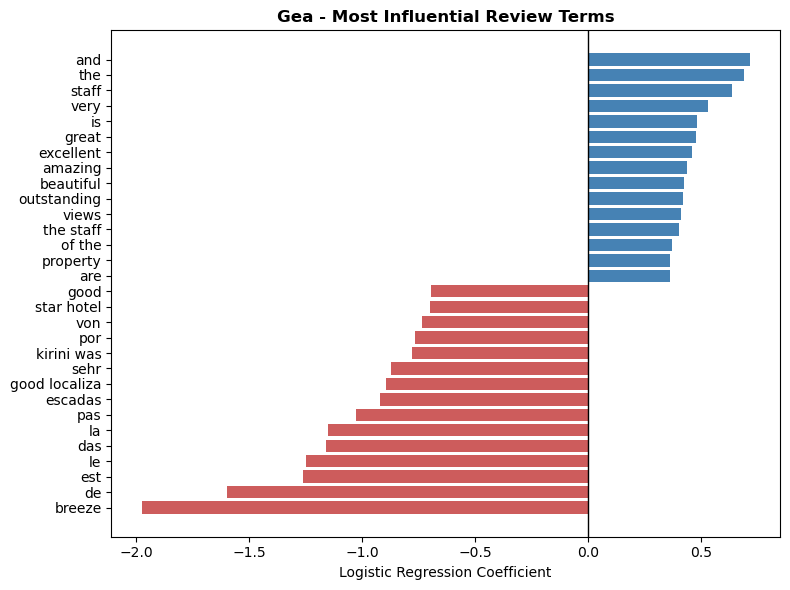

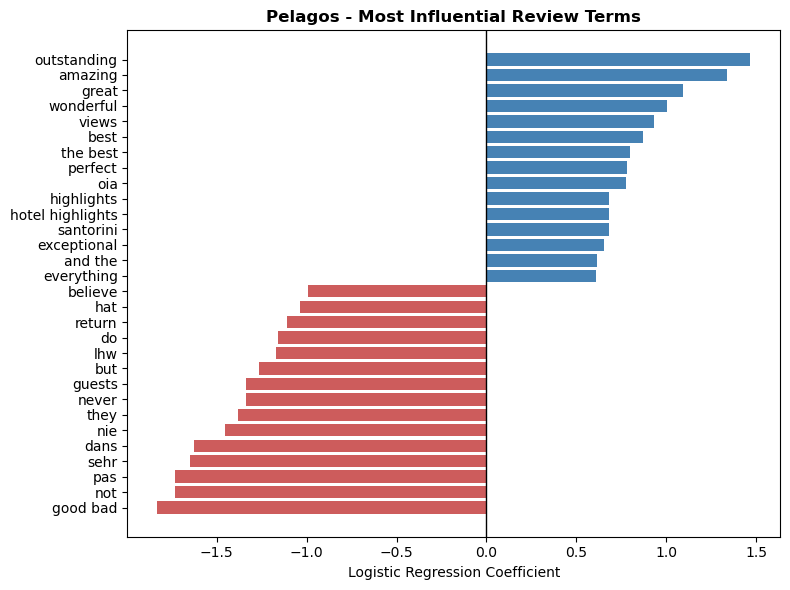

In [62]:
#Model Interpretability 
def plot_lr_features(model, hotel, top_n=15):
    vectorizer = model.named_steps["tfidf"]
    classifier = model.named_steps["classifier"]

    features = vectorizer.get_feature_names_out()
    coefficients = classifier.coef_[0]

# Confirm class 1 represents satisfied guests
    assert list(classifier.classes_) == [0, 1]

    negative_idx = np.argsort(coefficients)[:top_n]
    positive_idx = np.argsort(coefficients)[-top_n:][::-1]

    indices = np.concatenate([negative_idx, positive_idx])
    words = features[indices]
    values = coefficients[indices]

    colors = [
        "indianred" if value < 0 else "steelblue"
        for value in values
    ]

    order = np.argsort(values)

    plt.figure(figsize=(8, 6))
    plt.barh(
        words[order],
        values[order],
        color=np.array(colors)[order]
    )

    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Logistic Regression Coefficient")
    plt.title(
      f"{hotel} - Most Influential Review Terms",
      fontweight="bold"
    )
    plt.tight_layout()
    plt.savefig(
      f"{hotel}_Logistic_Regression_Features.png",
      dpi=300,
      bbox_inches="tight"
    )
    plt.show()

plot_lr_features(gea_lr, "Gea")
plot_lr_features(pelagos_lr, "Pelagos")

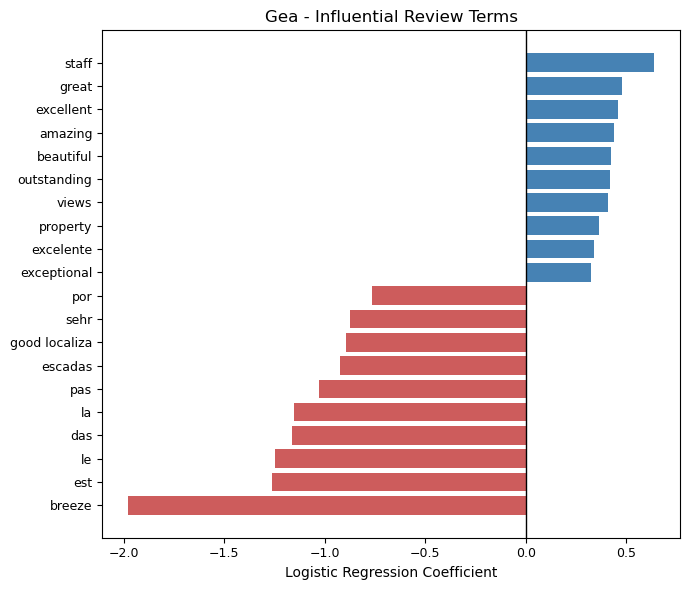

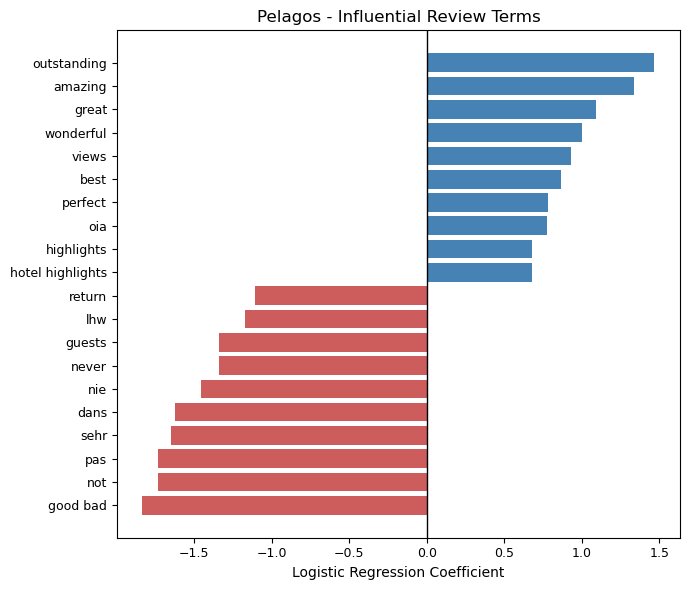

In [68]:
def plot_clean_features(model, hotel, top_n=10):
    vectorizer = model.named_steps["tfidf"]
    classifier = model.named_steps["classifier"]

    words = vectorizer.get_feature_names_out()
    coefficients = classifier.coef_[0]

# Filter display terms only
    stopwords = ENGLISH_STOP_WORDS - {"not", "never", "no"}

    valid = np.array([
        all(token not in stopwords
            for token in word.lower().split())
        for word in words
    ])

    words = words[valid]
    coefficients = coefficients[valid]

    negative = np.argsort(coefficients)[:top_n]
    positive = np.argsort(coefficients)[-top_n:]

    selected = np.concatenate([negative, positive])
    selected = selected[np.argsort(coefficients[selected])]

    plt.figure(figsize=(7, 6))

    plt.barh(
        words[selected],
        coefficients[selected],
        color=[
            "indianred" if x < 0 else "steelblue"
            for x in coefficients[selected]
        ]
    )

    plt.axvline(0, color="black", linewidth=1)
    plt.title(f"{hotel} - Influential Review Terms")
    plt.xlabel("Logistic Regression Coefficient")
    plt.xticks(fontsize=9)
    plt.yticks(fontsize=9)
    plt.tight_layout()

    plt.savefig(
        f"{hotel}_Clean_Features.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

plot_clean_features(gea_lr, "Gea")
plot_clean_features(pelagos_lr, "Pelagos")

In [69]:
def inspect_lr_terms(model, hotel):
    vectorizer = model.named_steps["tfidf"]
    classifier = model.named_steps["classifier"]

    words = vectorizer.get_feature_names_out()
    coefficients = classifier.coef_[0]

    results = pd.DataFrame({
        "Term": words,
        "Coefficient": coefficients
    })

    positive = results.nlargest(15, "Coefficient")
    negative = results.nsmallest(15, "Coefficient")

    print(f"\n{hotel} - POSITIVE TERMS")
    display(positive.round(3))

    print(f"\n{hotel} - NEGATIVE TERMS")
    display(negative.round(3))

inspect_lr_terms(gea_lr, "Gea")
inspect_lr_terms(pelagos_lr, "Pelagos")


Gea - POSITIVE TERMS


,Term,Coefficient
71,and,0.713
2544,the,0.690
2377,staff,0.636
2787,very,0.530
1235,is,0.480
997,great,0.478
731,excellent,0.458
58,amazing,0.438
169,beautiful,0.423
1876,outstanding,0.420



Gea - NEGATIVE TERMS


,Term,Coefficient
253,breeze,-1.976
475,de,-1.600
677,est,-1.264
1396,le,-1.249
460,das,-1.161
1383,la,-1.152
1911,pas,-1.027
668,escadas,-0.923
978,good localiza,-0.896
2249,sehr,-0.872



Pelagos - POSITIVE TERMS


,Term,Coefficient
1726,outstanding,1.468
65,amazing,1.336
961,great,1.092
2930,wonderful,1.004
2656,views,0.934
368,best,0.868
2275,the best,0.797
1769,perfect,0.784
1646,oia,0.778
1058,highlights,0.681



Pelagos - NEGATIVE TERMS


,Term,Coefficient
948,good bad,-1.832
1583,not,-1.733
1753,pas,-1.730
2003,sehr,-1.650
580,dans,-1.625
1564,nie,-1.454
2410,they,-1.381
1551,never,-1.337
982,guests,-1.336
424,but,-1.264


In [73]:
for hotel, model in [
    ("Gea", gea_lr),
    ("Pelagos", pelagos_lr)
]:
    tfidf = model.named_steps["tfidf"]

    print(f"\n{hotel}")
    print("Stopwords:", tfidf.stop_words)
    print("N-gram range:", tfidf.ngram_range)
    print("Max features:", tfidf.max_features)
    print("Min document frequency:", tfidf.min_df)
    print("Max document frequency:", tfidf.max_df)


Gea
Stopwords: None
N-gram range: (1, 2)
Max features: 3000
Min document frequency: 2
Max document frequency: 1.0

Pelagos
Stopwords: None
N-gram range: (1, 2)
Max features: 3000
Min document frequency: 2
Max document frequency: 1.0


In [78]:
for hotel, model in [
    ("Gea", gea_lr),
    ("Pelagos", pelagos_lr)
]:
    print(f"\n{hotel}")
    print("Pipeline steps:", list(model.named_steps.keys()))
    print("TD-IDF stopwords:", model.named_steps["tfidf"].stop_words)
    


Gea
Pipeline steps: ['tfidf', 'classifier']
TD-IDF stopwords: None

Pelagos
Pipeline steps: ['tfidf', 'classifier']
TD-IDF stopwords: None


In [81]:
print("Gea Training test example")
print(X_gea_train.head(5))
print("Pelagos Training test example")
print(X_pelagos_train.head(5))

Gea Training test example
179         very beautiful place and the staff excellant
72     highly recommended caldera view hotel in oia w...
85     amazing staff view and facility my wife and i ...
144    wundersch n aber nicht leading hotel of the wo...
212    santorini dreams came true good the property i...
Name: ML_Text, dtype: object
Pelagos Training test example
844    beautiful hotel with amazing views and the fri...
428         hotel highlights luxury great view high tech
251    paradise i want to start by give some folks th...
257    very luxurious hotel choice good very helpful ...
49     outstanding this is the best hotel in all of s...
Name: ML_Text, dtype: object


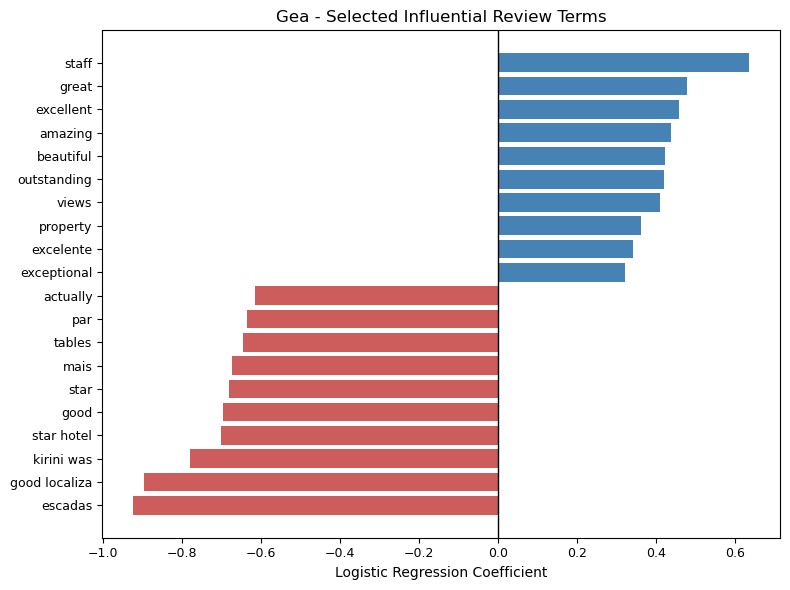

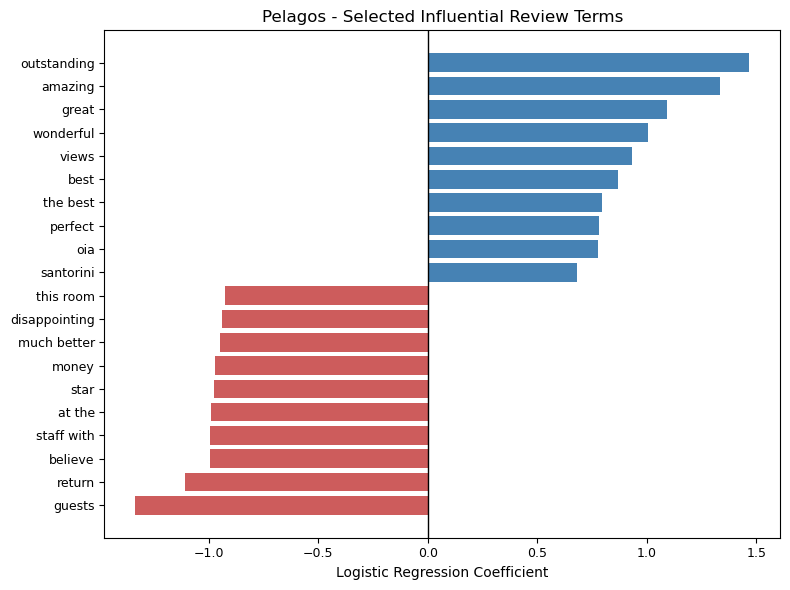

In [86]:
# Additional multilingual and uninformative terms
extra_stopwords = {
    "de", "la", "le", "les", "des", "das", "der",
    "die", "und", "von", "sehr", "pas", "est",
    "por", "dans", "nie", "lhw", "hat",
    "the staff", "of the", "and the",
    "good bad", "hotel highlights",
    "highlights", "breeze"
}

excluded_terms = set(ENGLISH_STOP_WORDS) | extra_stopwords

def plot_filtered_features(model, hotel, n=10):
    tfidf = model.named_steps["tfidf"]
    classifier = model.named_steps["classifier"]

    terms = tfidf.get_feature_names_out()
    coefficients = classifier.coef_[0]

# Exclude selected terms from visualization only
    selected = np.array([
        i for i, term in enumerate(terms)
        if term.lower() not in excluded_terms
    ])

    positive = selected[np.argsort(coefficients[selected])[-n:]]
    negative = selected[np.argsort(coefficients[selected])[:n]]

    indices = np.concatenate([negative, positive])
    indices = indices[np.argsort(coefficients[indices])]

    plt.figure(figsize=(8, 6))

    plt.barh(
        terms[indices],
        coefficients[indices],
        color=[
            "indianred" if coefficients[i] < 0 else "steelblue"
            for i in indices
        ]
     )
    plt.axvline(0, color="black", linewidth=1)
    plt.title(f"{hotel} - Selected Influential Review Terms")
    plt.xlabel("Logistic Regression Coefficient")
    plt.xticks(fontsize=9)
    plt.yticks(fontsize=9)
    plt.tight_layout()

    plt.savefig(
        f"{hotel}_Filtered_Features.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

plot_filtered_features(gea_lr, "Gea")
plot_filtered_features(pelagos_lr, "Pelagos")